In [1]:
import sys
print(sys.executable)

c:\Users\rohan\OneDrive\Desktop\Home Credit Project\venv311\Scripts\python.exe


In [2]:
# ── Cell 1: Imports and Setup ──────────────────────────────────────────────

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Paths
BASE_DIR = Path(r"C:\Users\rohan\OneDrive\Desktop\Home Credit Project")
DATA_DIR = BASE_DIR / "data"
DB_PATH  = BASE_DIR / "outputs" / "home_credit.duckdb"

# Plot styling
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.spines.top"]   = False
plt.rcParams["axes.spines.right"] = False
sns.set_palette("Blues_r")

print("✓ Imports successful")
print(f"✓ Data directory: {DATA_DIR}")
print(f"✓ Database will be saved to: {DB_PATH}")

✓ Imports successful
✓ Data directory: C:\Users\rohan\OneDrive\Desktop\Home Credit Project\data
✓ Database will be saved to: C:\Users\rohan\OneDrive\Desktop\Home Credit Project\outputs\home_credit.duckdb


In [3]:
# ── Cell 2: Load CSVs into DuckDB ─────────────────────────────────────────

con = duckdb.connect(str(DB_PATH))

# Skipping columns_description — encoding issue, not needed for analysis
tables = {
    "application_train"      : "application_train.csv",
    "application_test"       : "application_test.csv",
    "bureau"                 : "bureau.csv",
    "bureau_balance"         : "bureau_balance.csv",
    "previous_application"   : "previous_application.csv",
    "pos_cash_balance"       : "POS_CASH_balance.csv",
    "credit_card_balance"    : "credit_card_balance.csv",
    "installments_payments"  : "installments_payments.csv",
}

print("Loading tables into DuckDB...\n")
for table_name, filename in tables.items():
    file_path = DATA_DIR / filename
    con.execute(f"""
        CREATE OR REPLACE TABLE {table_name} AS
        SELECT * FROM read_csv_auto('{file_path.as_posix()}', 
                                     header=True,
                                     ignore_errors=True)
    """)
    row_count = con.execute(f"SELECT COUNT(*) FROM {table_name}").fetchone()[0]
    print(f"  ✓ {table_name:<30} {row_count:>10,} rows")

print("\n✓ All tables loaded successfully")

Loading tables into DuckDB...

  ✓ application_train                 307,511 rows
  ✓ application_test                   48,744 rows
  ✓ bureau                          1,716,428 rows
  ✓ bureau_balance                 27,299,925 rows
  ✓ previous_application            1,670,214 rows
  ✓ pos_cash_balance               10,001,358 rows
  ✓ credit_card_balance             3,840,312 rows
  ✓ installments_payments          13,605,401 rows

✓ All tables loaded successfully


In [4]:
# ── Cell 3: Build Feature Mart ─────────────────────────────────────────────

# What we're doing:
# 1. Start with application_train (one row per applicant)
# 2. Aggregate bureau data up to applicant level (prior credits at other banks)
# 3. Aggregate previous_application up to applicant level (prior Home Credit loans)
# 4. Aggregate installments_payments up to applicant level (payment behaviour)
# 5. Join everything together on SK_ID_CURR (the applicant ID)

con.execute("""
CREATE OR REPLACE TABLE feature_mart AS

WITH 

-- ── Bureau Aggregation ───────────────────────────────────────────────────
-- Each applicant may have multiple prior credits at other institutions
-- We summarise them into counts, averages, and max values
bureau_agg AS (
    SELECT
        SK_ID_CURR,
        COUNT(*)                                    AS bureau_loan_count,
        AVG(AMT_CREDIT_SUM)                         AS bureau_avg_credit_amount,
        SUM(AMT_CREDIT_SUM_DEBT)                    AS bureau_total_debt,
        AVG(DAYS_CREDIT)                            AS bureau_avg_days_credit,
        SUM(CASE WHEN CREDIT_ACTIVE = 'Active' 
                 THEN 1 ELSE 0 END)                 AS bureau_active_loans,
        SUM(CASE WHEN AMT_CREDIT_SUM_OVERDUE > 0 
                 THEN 1 ELSE 0 END)                 AS bureau_overdue_count
    FROM bureau
    GROUP BY SK_ID_CURR
),

-- ── Previous Application Aggregation ────────────────────────────────────
-- Each applicant may have applied to Home Credit before
-- We capture how many times, approval rate, and average loan requested
prev_app_agg AS (
    SELECT
        SK_ID_CURR,
        COUNT(*)                                    AS prev_app_count,
        AVG(AMT_APPLICATION)                        AS prev_avg_loan_requested,
        AVG(AMT_CREDIT)                             AS prev_avg_loan_approved,
        SUM(CASE WHEN NAME_CONTRACT_STATUS = 'Approved' 
                 THEN 1 ELSE 0 END)                 AS prev_approved_count,
        SUM(CASE WHEN NAME_CONTRACT_STATUS = 'Refused' 
                 THEN 1 ELSE 0 END)                 AS prev_refused_count
    FROM previous_application
    GROUP BY SK_ID_CURR
),

-- ── Installments Payment Behaviour ──────────────────────────────────────
-- How reliably has this applicant repaid previous Home Credit loans?
-- Late payments and payment ratios are strong default predictors
install_agg AS (
    SELECT
        SK_ID_CURR,
        COUNT(*)                                        AS install_total_payments,
        AVG(AMT_PAYMENT / NULLIF(AMT_INSTALMENT, 0))   AS install_payment_ratio,
        SUM(CASE WHEN DAYS_ENTRY_PAYMENT > DAYS_INSTALMENT 
                 THEN 1 ELSE 0 END)                     AS install_late_payments,
        AVG(DAYS_ENTRY_PAYMENT - DAYS_INSTALMENT)       AS install_avg_days_late
    FROM installments_payments
    GROUP BY SK_ID_CURR
)

-- ── Final Join ───────────────────────────────────────────────────────────
-- Bring everything together on SK_ID_CURR
-- LEFT JOINs because not every applicant has bureau or previous app history
-- NULL values here are meaningful — they mean no prior credit history
SELECT
    -- Core applicant info
    a.SK_ID_CURR,
    a.TARGET,
    a.NAME_CONTRACT_TYPE,
    a.CODE_GENDER,
    a.FLAG_OWN_CAR,
    a.FLAG_OWN_REALTY,
    a.CNT_CHILDREN,
    a.AMT_INCOME_TOTAL,
    a.AMT_CREDIT,
    a.AMT_ANNUITY,
    a.NAME_INCOME_TYPE,
    a.NAME_EDUCATION_TYPE,
    a.NAME_FAMILY_STATUS,
    a.DAYS_BIRTH,
    a.DAYS_EMPLOYED,
    a.DAYS_REGISTRATION,
    a.DAYS_ID_PUBLISH,
    a.REGION_POPULATION_RELATIVE,
    a.EXT_SOURCE_1,
    a.EXT_SOURCE_2,
    a.EXT_SOURCE_3,

    -- Derived features from application
    ROUND(a.AMT_CREDIT / NULLIF(a.AMT_INCOME_TOTAL, 0), 2)   AS credit_income_ratio,
    ROUND(a.AMT_ANNUITY / NULLIF(a.AMT_INCOME_TOTAL, 0), 2)  AS annuity_income_ratio,
    ROUND(a.DAYS_BIRTH / -365.0, 1)                           AS age_years,
    CASE WHEN a.DAYS_EMPLOYED = 365243 
         THEN NULL 
         ELSE ROUND(a.DAYS_EMPLOYED / -365.0, 1) 
    END                                                        AS employment_years,

    -- Bureau features
    b.bureau_loan_count,
    b.bureau_avg_credit_amount,
    b.bureau_total_debt,
    b.bureau_avg_days_credit,
    b.bureau_active_loans,
    b.bureau_overdue_count,

    -- Previous application features
    p.prev_app_count,
    p.prev_avg_loan_requested,
    p.prev_avg_loan_approved,
    p.prev_approved_count,
    p.prev_refused_count,

    -- Payment behaviour features
    i.install_total_payments,
    i.install_payment_ratio,
    i.install_late_payments,
    i.install_avg_days_late

FROM application_train a
LEFT JOIN bureau_agg      b ON a.SK_ID_CURR = b.SK_ID_CURR
LEFT JOIN prev_app_agg    p ON a.SK_ID_CURR = p.SK_ID_CURR
LEFT JOIN install_agg     i ON a.SK_ID_CURR = i.SK_ID_CURR
""")

row_count = con.execute("SELECT COUNT(*) FROM feature_mart").fetchone()[0]
col_count = len(con.execute("SELECT * FROM feature_mart LIMIT 1").description)
print(f"✓ feature_mart created: {row_count:,} rows × {col_count} columns")

✓ feature_mart created: 307,511 rows × 40 columns


In [5]:
# ── Cell 4: Sanity Check ───────────────────────────────────────────────────

# 1. Preview the first 5 rows
print("=== SAMPLE ROWS ===")
sample = con.execute("SELECT * FROM feature_mart LIMIT 5").df()
print(sample.head())

# 2. Target distribution — how many defaulters vs non-defaulters?
print("\n=== TARGET DISTRIBUTION ===")
target_dist = con.execute("""
    SELECT 
        TARGET,
        COUNT(*)                                        AS count,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(), 2) AS pct
    FROM feature_mart
    GROUP BY TARGET
    ORDER BY TARGET
""").df()
print(target_dist)

# 3. Null rates for key columns — how much data is missing?
print("\n=== NULL RATES FOR KEY COLUMNS ===")
null_check = con.execute("""
    SELECT
        ROUND(AVG(CASE WHEN EXT_SOURCE_1        IS NULL THEN 1.0 ELSE 0.0 END)*100, 1) AS ext_source_1_null_pct,
        ROUND(AVG(CASE WHEN EXT_SOURCE_2        IS NULL THEN 1.0 ELSE 0.0 END)*100, 1) AS ext_source_2_null_pct,
        ROUND(AVG(CASE WHEN EXT_SOURCE_3        IS NULL THEN 1.0 ELSE 0.0 END)*100, 1) AS ext_source_3_null_pct,
        ROUND(AVG(CASE WHEN bureau_loan_count   IS NULL THEN 1.0 ELSE 0.0 END)*100, 1) AS bureau_null_pct,
        ROUND(AVG(CASE WHEN prev_app_count      IS NULL THEN 1.0 ELSE 0.0 END)*100, 1) AS prev_app_null_pct,
        ROUND(AVG(CASE WHEN install_late_payments IS NULL THEN 1.0 ELSE 0.0 END)*100, 1) AS install_null_pct,
        ROUND(AVG(CASE WHEN employment_years    IS NULL THEN 1.0 ELSE 0.0 END)*100, 1) AS employment_null_pct
    FROM feature_mart
""").df()
print(null_check.T.rename(columns={0: "null_%"}))

=== SAMPLE ROWS ===
   SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR  \
0      374516       0    Revolving loans           F            N   
1      374517       0         Cash loans           M            Y   
2      374520       0         Cash loans           M            N   
3      374521       0         Cash loans           M            N   
4      374522       0         Cash loans           M            Y   

  FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
0               Y             1          315000.0    675000.0      33750.0   
1               Y             0          324000.0    592560.0      35937.0   
2               Y             0          112500.0    485640.0      41674.5   
3               Y             0          225000.0    555273.0      18040.5   
4               N             0           40500.0     85320.0       6313.5   

   ... bureau_overdue_count prev_app_count prev_avg_loan_requested  \
0  ...                  0.

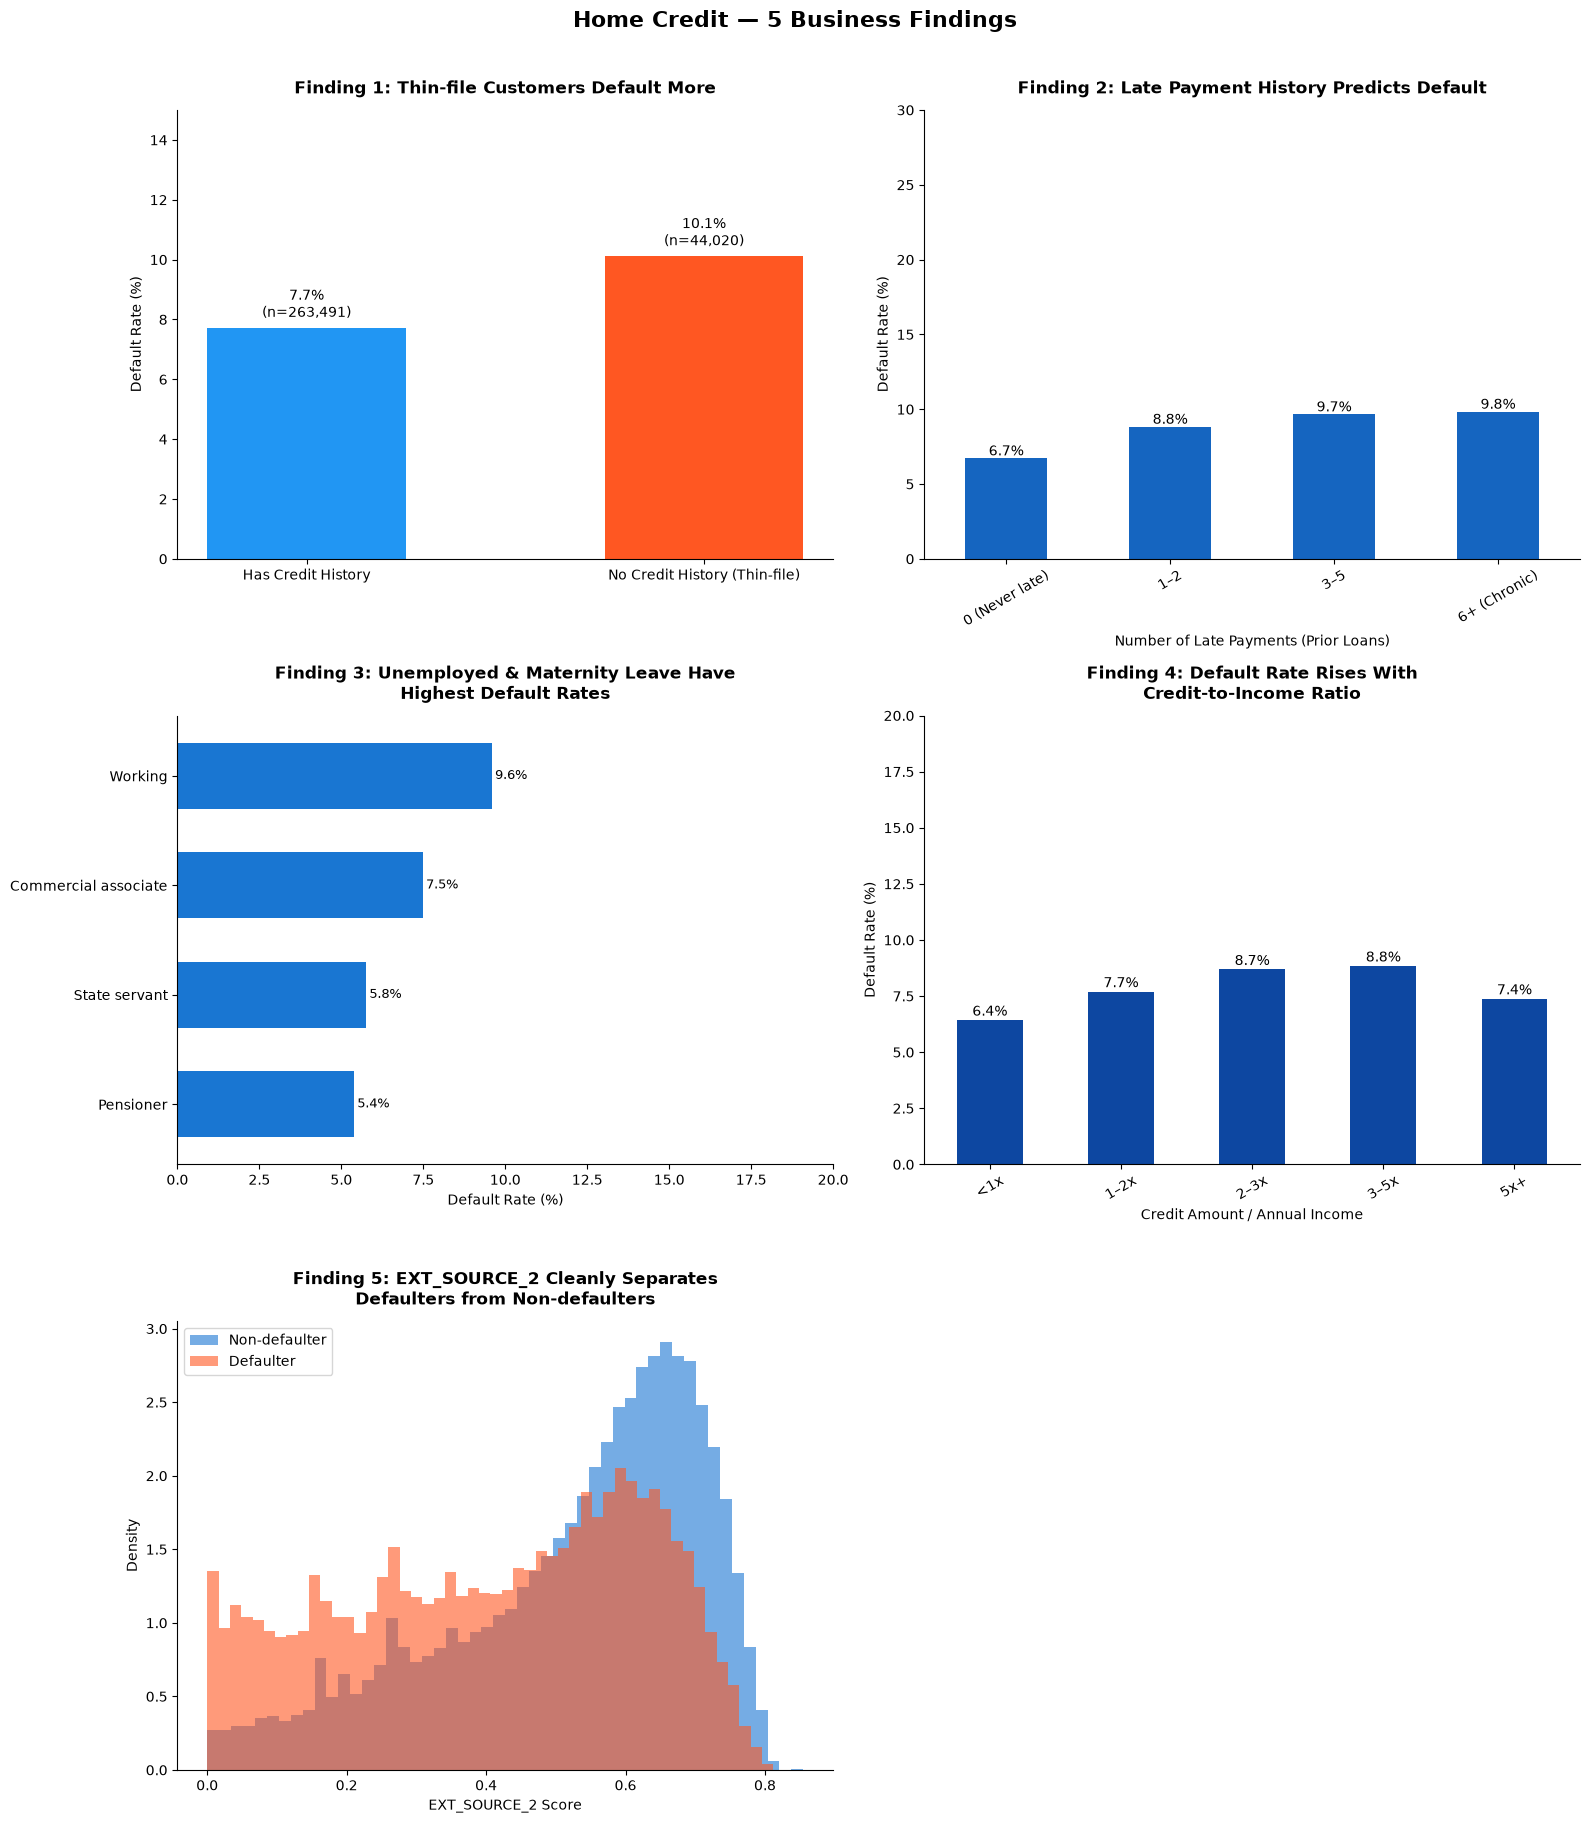

✓ EDA chart saved to outputs/eda_findings.png


In [6]:
# ── Cell 5: EDA — 5 Business Findings ─────────────────────────────────────

df = con.execute("SELECT * FROM feature_mart").df()

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
fig.suptitle("Home Credit — 5 Business Findings", 
             fontsize=16, fontweight='bold', y=1.01)

# ── Finding 1: Thin-file customers default more ───────────────────────────
ax1 = axes[0, 0]
df['has_bureau'] = df['bureau_loan_count'].notna().map(
    {True: 'Has Credit History', False: 'No Credit History (Thin-file)'}
)
thin_file = df.groupby('has_bureau')['TARGET'].agg(['mean', 'count']).reset_index()
thin_file['mean'] = thin_file['mean'] * 100

bars = ax1.bar(thin_file['has_bureau'], thin_file['mean'], 
               color=['#2196F3', '#FF5722'], width=0.5)
ax1.set_title('Finding 1: Thin-file Customers Default More', 
              fontweight='bold', pad=12)
ax1.set_ylabel('Default Rate (%)')
ax1.set_xlabel('')
for bar, (_, row) in zip(bars, thin_file.iterrows()):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             f"{row['mean']:.1f}%\n(n={row['count']:,})", 
             ha='center', va='bottom', fontsize=10)
ax1.set_ylim(0, 15)

# ── Finding 2: Late payments strongly predict default ─────────────────────
ax2 = axes[0, 1]
df['late_payment_band'] = pd.cut(
    df['install_late_payments'].fillna(0),
    bins=[-1, 0, 2, 5, 1000],
    labels=['0 (Never late)', '1–2', '3–5', '6+ (Chronic)']
)
late_default = df.groupby('late_payment_band', observed=True)['TARGET'].mean() * 100
late_default.plot(kind='bar', ax=ax2, color='#1565C0', width=0.5)
ax2.set_title('Finding 2: Late Payment History Predicts Default', 
              fontweight='bold', pad=12)
ax2.set_ylabel('Default Rate (%)')
ax2.set_xlabel('Number of Late Payments (Prior Loans)')
ax2.tick_params(axis='x', rotation=30)
for i, v in enumerate(late_default):
    ax2.text(i, v + 0.2, f'{v:.1f}%', ha='center', fontsize=10)
ax2.set_ylim(0, 30)

# ── Finding 3: Income type default rates ──────────────────────────────────
ax3 = axes[1, 0]
income_default = (df.groupby('NAME_INCOME_TYPE')['TARGET']
                  .agg(['mean', 'count'])
                  .query('count > 500')
                  .sort_values('mean', ascending=True))
income_default['mean'] = income_default['mean'] * 100
income_default['mean'].plot(kind='barh', ax=ax3, color='#1976D2', width=0.6)
ax3.set_title('Finding 3: Unemployed & Maternity Leave Have\nHighest Default Rates', 
              fontweight='bold', pad=12)
ax3.set_xlabel('Default Rate (%)')
ax3.set_ylabel('')
for i, v in enumerate(income_default['mean']):
    ax3.text(v + 0.1, i, f'{v:.1f}%', va='center', fontsize=9)
ax3.set_xlim(0, 20)

# ── Finding 4: Credit-to-income ratio vs default ──────────────────────────
ax4 = axes[1, 1]
df['cir_band'] = pd.cut(
    df['credit_income_ratio'].clip(0, 10),
    bins=[0, 1, 2, 3, 5, 10],
    labels=['<1x', '1–2x', '2–3x', '3–5x', '5x+']
)
cir_default = df.groupby('cir_band', observed=True)['TARGET'].mean() * 100
cir_default.plot(kind='bar', ax=ax4, color='#0D47A1', width=0.5)
ax4.set_title('Finding 4: Default Rate Rises With\nCredit-to-Income Ratio', 
              fontweight='bold', pad=12)
ax4.set_ylabel('Default Rate (%)')
ax4.set_xlabel('Credit Amount / Annual Income')
ax4.tick_params(axis='x', rotation=30)
for i, v in enumerate(cir_default):
    ax4.text(i, v + 0.2, f'{v:.1f}%', ha='center', fontsize=10)
ax4.set_ylim(0, 20)

# ── Finding 5: EXT_SOURCE_2 clearly separates defaulters ─────────────────
ax5 = axes[2, 0]
defaulters     = df[df['TARGET'] == 1]['EXT_SOURCE_2'].dropna()
non_defaulters = df[df['TARGET'] == 0]['EXT_SOURCE_2'].dropna()
ax5.hist(non_defaulters, bins=50, alpha=0.6, color='#1976D2', 
         label='Non-defaulter', density=True)
ax5.hist(defaulters,     bins=50, alpha=0.6, color='#FF5722', 
         label='Defaulter',     density=True)
ax5.set_title('Finding 5: EXT_SOURCE_2 Cleanly Separates\nDefaulters from Non-defaulters', 
              fontweight='bold', pad=12)
ax5.set_xlabel('EXT_SOURCE_2 Score')
ax5.set_ylabel('Density')
ax5.legend()

# ── Hide the unused 6th subplot ───────────────────────────────────────────
axes[2, 1].axis('off')

plt.tight_layout()
plt.savefig(BASE_DIR / "outputs" / "eda_findings.png", 
            dpi=150, bbox_inches='tight')
plt.show()
print("✓ EDA chart saved to outputs/eda_findings.png")

Training set:   246,008 rows
Validation set: 61,503 rows
Default rate — train: 8.07%, val: 8.07%

Training model — this will take 2-3 minutes...
✓ Model trained
✓ Validation AUC: 0.7559


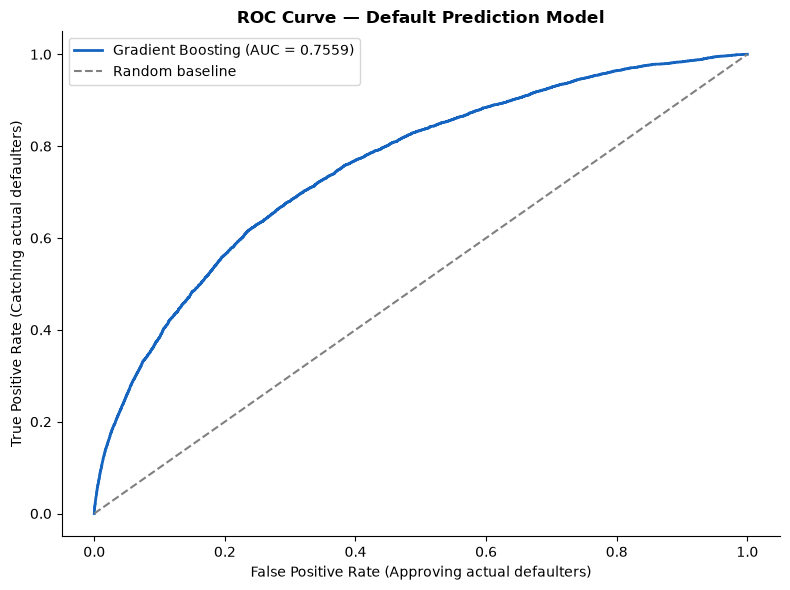


Calculating feature importance — this will take 1-2 minutes...


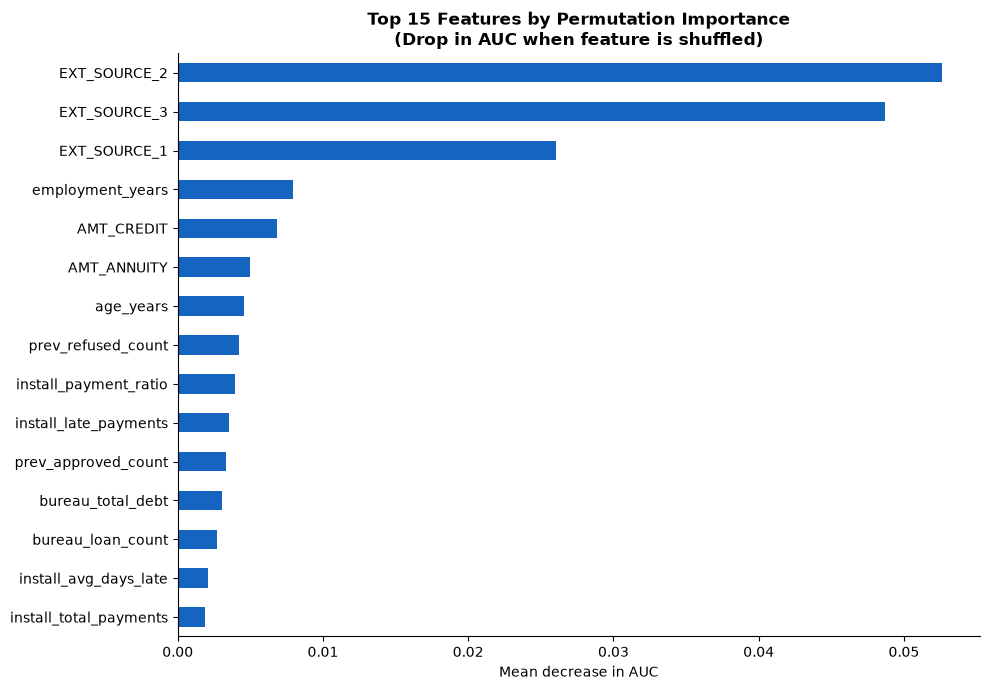

✓ ROC curve saved
✓ Feature importance saved
✓ Validation predictions ready for policy simulation


In [7]:
# ── Cell 6: Gradient Boosting Model (scikit-learn) ─────────────────────────

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings('ignore')

# ── 1. Prepare features ───────────────────────────────────────────────────
feature_cols = [
    'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
    'CNT_CHILDREN', 'REGION_POPULATION_RELATIVE',
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3',
    'credit_income_ratio', 'annuity_income_ratio',
    'age_years', 'employment_years',
    'bureau_loan_count', 'bureau_avg_credit_amount',
    'bureau_total_debt', 'bureau_active_loans', 'bureau_overdue_count',
    'prev_app_count', 'prev_avg_loan_requested',
    'prev_approved_count', 'prev_refused_count',
    'install_total_payments', 'install_payment_ratio',
    'install_late_payments', 'install_avg_days_late'
]

X = df[feature_cols]
y = df['TARGET']

# ── 2. Train/validation split ─────────────────────────────────────────────
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training set:   {X_train.shape[0]:,} rows")
print(f"Validation set: {X_val.shape[0]:,} rows")
print(f"Default rate — train: {y_train.mean():.2%}, val: {y_val.mean():.2%}")

# ── 3. Train Model ────────────────────────────────────────────────────────
print("\nTraining model — this will take 2-3 minutes...")

model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    min_samples_leaf=100,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)
print("✓ Model trained")

# ── 4. Evaluate ───────────────────────────────────────────────────────────
val_preds = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, val_preds)
print(f"✓ Validation AUC: {auc:.4f}")

# ── 5. ROC Curve ──────────────────────────────────────────────────────────
fpr, tpr, thresholds = roc_curve(y_val, val_preds)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, color='#1565C0', lw=2,
        label=f'Gradient Boosting (AUC = {auc:.4f})')
ax.plot([0, 1], [0, 1], color='gray',
        linestyle='--', label='Random baseline')
ax.set_xlabel('False Positive Rate (Approving actual defaulters)')
ax.set_ylabel('True Positive Rate (Catching actual defaulters)')
ax.set_title('ROC Curve — Default Prediction Model', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(BASE_DIR / "outputs" / "roc_curve.png", dpi=150, bbox_inches='tight')
plt.show()

# ── 6. Feature Importance (permutation-based) ─────────────────────────────
# HistGradientBoostingClassifier doesn't have feature_importances_ directly
# Permutation importance measures how much AUC drops when each feature is shuffled
# A bigger drop = more important feature
print("\nCalculating feature importance — this will take 1-2 minutes...")

perm_imp = permutation_importance(
    model, X_val, y_val,
    n_repeats=5,
    random_state=42,
    scoring='roc_auc',
    n_jobs=-1
)

importance = pd.Series(
    perm_imp.importances_mean,
    index=feature_cols
).sort_values(ascending=True).tail(15)

fig, ax = plt.subplots(figsize=(10, 7))
importance.plot(kind='barh', ax=ax, color='#1565C0')
ax.set_title('Top 15 Features by Permutation Importance\n(Drop in AUC when feature is shuffled)',
             fontweight='bold')
ax.set_xlabel('Mean decrease in AUC')
plt.tight_layout()
plt.savefig(BASE_DIR / "outputs" / "feature_importance.png",
            dpi=150, bbox_inches='tight')
plt.show()

# ── 7. Save predictions for policy simulation ─────────────────────────────
df_val = X_val.copy()
df_val['TARGET'] = y_val
df_val['predicted_proba'] = val_preds

print("✓ ROC curve saved")
print("✓ Feature importance saved")
print("✓ Validation predictions ready for policy simulation")

Revenue per good loan:    270,000
Loss per bad loan:        200,000
Max bad rate allowed:     5.0%

── Optimal Policy (bad rate ≤ 5.0%) ──────────────
Cut-off:                  0.61
Approval rate:            80.7%
Bad rate:                 4.9%
Total portfolio profit:   12.25B


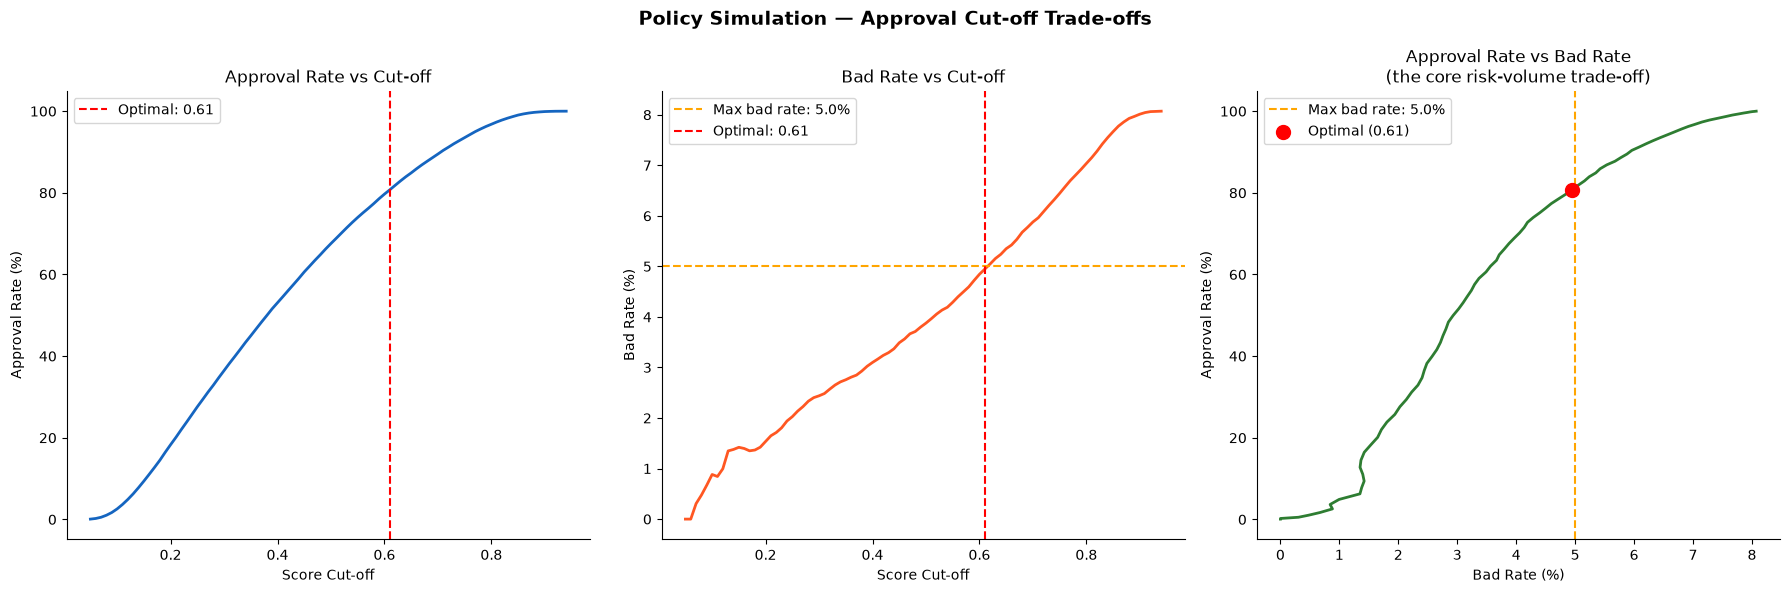


── Business Recommendation ──────────────────────────────────────

Under a board-mandated bad rate ceiling of 5.0%, the 
recommended approval cut-off is 0.61.

This policy:
  • Approves 80.7% of applicants
  • Maintains a bad rate of 4.9% (within the 5.0% limit)
  • Generates a total portfolio profit of 12.25B

Tightening to 0.55:
  • Reduces bad rate by 0.7pp
  • Costs 886M in foregone profit

Assumptions: Avg loan = 500,000 | Margin = 18% | 
             Term = 3yr | LGD = 40% |
             Bad rate ceiling = 5.0%



In [8]:
# ── Cell 7: Policy Simulation (with bad rate constraint) ──────────────────

# Real lenders don't just maximise profit — they operate under a risk appetite
# set by their board. A typical constraint: bad rate must not exceed X%.
# We find the cut-off that maximises approval volume within that constraint.

# ── Business Assumptions ─────────────────────────────────────────────────
AVG_LOAN              = 500_000
INTEREST_MARGIN       = 0.18
LOAN_TERM_YEARS       = 3
LOSS_GIVEN_DEFAULT    = 0.40
MAX_BAD_RATE          = 5.0    # Board-mandated risk appetite: max 5% bad rate

REVENUE_PER_GOOD_LOAN = AVG_LOAN * INTEREST_MARGIN * LOAN_TERM_YEARS
LOSS_PER_BAD_LOAN     = AVG_LOAN * LOSS_GIVEN_DEFAULT

print(f"Revenue per good loan:    {REVENUE_PER_GOOD_LOAN:,.0f}")
print(f"Loss per bad loan:        {LOSS_PER_BAD_LOAN:,.0f}")
print(f"Max bad rate allowed:     {MAX_BAD_RATE}%")

# ── Sweep cut-offs ────────────────────────────────────────────────────────
cutoffs        = np.arange(0.05, 0.95, 0.01)
approval_rates = []
bad_rates      = []
total_profits  = []

total = len(df_val)

for cutoff in cutoffs:
    approved = df_val[df_val['predicted_proba'] <= cutoff]

    if len(approved) == 0:
        approval_rates.append(0)
        bad_rates.append(0)
        total_profits.append(0)
        continue

    n_approved = len(approved)
    n_bad      = approved['TARGET'].sum()
    n_good     = n_approved - n_bad

    approval_rates.append(n_approved / total * 100)
    bad_rates.append(n_bad / n_approved * 100)
    total_profits.append(n_good * REVENUE_PER_GOOD_LOAN - 
                         n_bad  * LOSS_PER_BAD_LOAN)

approval_rates = np.array(approval_rates)
bad_rates      = np.array(bad_rates)
total_profits  = np.array(total_profits)

# ── Find optimal cut-off WITHIN bad rate constraint ───────────────────────
# Among all cut-offs where bad rate <= MAX_BAD_RATE,
# pick the one with the highest approval rate (most volume)
feasible_mask  = bad_rates <= MAX_BAD_RATE
feasible_cutoffs     = cutoffs[feasible_mask]
feasible_approval    = approval_rates[feasible_mask]
feasible_bad         = bad_rates[feasible_mask]
feasible_profit      = total_profits[feasible_mask]

if len(feasible_cutoffs) == 0:
    print("No cut-off achieves the target bad rate. Relax the constraint.")
else:
    optimal_idx      = np.argmax(feasible_approval)
    optimal_cutoff   = feasible_cutoffs[optimal_idx]
    optimal_approval = feasible_approval[optimal_idx]
    optimal_bad_rate = feasible_bad[optimal_idx]
    optimal_profit   = feasible_profit[optimal_idx]

    print(f"\n── Optimal Policy (bad rate ≤ {MAX_BAD_RATE}%) ──────────────")
    print(f"Cut-off:                  {optimal_cutoff:.2f}")
    print(f"Approval rate:            {optimal_approval:.1f}%")
    print(f"Bad rate:                 {optimal_bad_rate:.1f}%")
    print(f"Total portfolio profit:   {optimal_profit/1e9:.2f}B")

# ── Plot ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Policy Simulation — Approval Cut-off Trade-offs',
             fontsize=14, fontweight='bold')

# Panel 1: Approval Rate
axes[0].plot(cutoffs, approval_rates, color='#1565C0', lw=2)
axes[0].axvline(optimal_cutoff, color='red', linestyle='--',
                label=f'Optimal: {optimal_cutoff:.2f}')
axes[0].set_xlabel('Score Cut-off')
axes[0].set_ylabel('Approval Rate (%)')
axes[0].set_title('Approval Rate vs Cut-off')
axes[0].legend()

# Panel 2: Bad Rate with constraint line
axes[1].plot(cutoffs, bad_rates, color='#FF5722', lw=2)
axes[1].axhline(MAX_BAD_RATE, color='orange', linestyle='--',
                label=f'Max bad rate: {MAX_BAD_RATE}%')
axes[1].axvline(optimal_cutoff, color='red', linestyle='--',
                label=f'Optimal: {optimal_cutoff:.2f}')
axes[1].set_xlabel('Score Cut-off')
axes[1].set_ylabel('Bad Rate (%)')
axes[1].set_title('Bad Rate vs Cut-off')
axes[1].legend()

# Panel 3: Approval rate vs bad rate (the core trade-off curve)
axes[2].plot(bad_rates, approval_rates, color='#2E7D32', lw=2)
axes[2].axvline(MAX_BAD_RATE, color='orange', linestyle='--',
                label=f'Max bad rate: {MAX_BAD_RATE}%')
axes[2].scatter([optimal_bad_rate], [optimal_approval], 
                color='red', zorder=5, s=100,
                label=f'Optimal ({optimal_cutoff:.2f})')
axes[2].set_xlabel('Bad Rate (%)')
axes[2].set_ylabel('Approval Rate (%)')
axes[2].set_title('Approval Rate vs Bad Rate\n(the core risk-volume trade-off)')
axes[2].legend()

plt.tight_layout()
plt.savefig(BASE_DIR / "outputs" / "policy_simulation.png",
            dpi=150, bbox_inches='tight')
plt.show()

# ── Business Recommendation ───────────────────────────────────────────────
# What does tightening the cut-off by 0.05 cost?
tighter_mask  = feasible_cutoffs <= optimal_cutoff - 0.05
if tighter_mask.sum() > 0:
    tighter_idx      = np.argmax(feasible_approval[tighter_mask])
    tighter_cutoff   = feasible_cutoffs[tighter_mask][tighter_idx]
    tighter_approval = feasible_approval[tighter_mask][tighter_idx]
    tighter_bad      = feasible_bad[tighter_mask][tighter_idx]
    tighter_profit   = feasible_profit[tighter_mask][tighter_idx]
    profit_cost      = optimal_profit - tighter_profit
    bad_rate_saving  = optimal_bad_rate - tighter_bad
else:
    profit_cost     = 0
    bad_rate_saving = 0
    tighter_cutoff  = optimal_cutoff

print(f"""
── Business Recommendation ──────────────────────────────────────

Under a board-mandated bad rate ceiling of {MAX_BAD_RATE}%, the 
recommended approval cut-off is {optimal_cutoff:.2f}.

This policy:
  • Approves {optimal_approval:.1f}% of applicants
  • Maintains a bad rate of {optimal_bad_rate:.1f}% (within the {MAX_BAD_RATE}% limit)
  • Generates a total portfolio profit of {optimal_profit/1e9:.2f}B

Tightening to {tighter_cutoff:.2f}:
  • Reduces bad rate by {bad_rate_saving:.1f}pp
  • Costs {profit_cost/1e6:.0f}M in foregone profit

Assumptions: Avg loan = {AVG_LOAN:,} | Margin = {INTEREST_MARGIN:.0%} | 
             Term = {LOAN_TERM_YEARS}yr | LGD = {LOSS_GIVEN_DEFAULT:.0%} |
             Bad rate ceiling = {MAX_BAD_RATE}%
""")

In [9]:
# ── Cell 8: Limitations & Next Steps ──────────────────────────────────────

print("""
── Model Limitations ────────────────────────────────────────────

1. REJECT INFERENCE BIAS
   The model is trained only on approved applicants — those who 
   were previously granted a loan. Rejected applicants have no 
   TARGET label. This means the model may underestimate risk for 
   applicant profiles that were historically rejected. A production 
   deployment would require champion-challenger testing to address this.

2. EXT_SOURCE OPACITY
   The three strongest predictors (EXT_SOURCE_1, 2, 3) are external 
   risk scores from an unknown provider. Their inputs are not disclosed. 
   In a regulated market, this creates a model governance problem — 
   the lender cannot explain to a regulator or applicant why they 
   were rejected based on these scores.

3. TEMPORAL VALIDITY
   The dataset is from a single point in time. Default rates shift 
   with macroeconomic cycles. A model trained on 2018 data may not 
   perform as well in a recession or rate-rise environment.

4. BUSINESS ASSUMPTIONS
   The policy simulation uses assumed values for loan size, margin, 
   and loss given default. The optimal cut-off is sensitive to these 
   inputs. A sensitivity analysis across assumption ranges would 
   strengthen the recommendation.

── Next Steps ───────────────────────────────────────────────────

1. WoE/IV Scorecard — build an explainable logistic regression 
   scorecard for regulatory compliance and credit committee review

2. Fairness Audit — test whether the 0.61 cut-off produces 
   disparate approval rates across gender and income type segments

3. Streamlit App — interactive dashboard for credit officers to 
   adjust the cut-off and see trade-offs in real time

4. Sensitivity Analysis — test how the optimal cut-off shifts 
   under different LGD and margin assumptions
""")


── Model Limitations ────────────────────────────────────────────

1. REJECT INFERENCE BIAS
   The model is trained only on approved applicants — those who 
   were previously granted a loan. Rejected applicants have no 
   TARGET label. This means the model may underestimate risk for 
   applicant profiles that were historically rejected. A production 
   deployment would require champion-challenger testing to address this.

2. EXT_SOURCE OPACITY
   The three strongest predictors (EXT_SOURCE_1, 2, 3) are external 
   risk scores from an unknown provider. Their inputs are not disclosed. 
   In a regulated market, this creates a model governance problem — 
   the lender cannot explain to a regulator or applicant why they 
   were rejected based on these scores.

3. TEMPORAL VALIDITY
   The dataset is from a single point in time. Default rates shift 
   with macroeconomic cycles. A model trained on 2018 data may not 
   perform as well in a recession or rate-rise environment.

4. BUSINE

Preparing sample...
Sample shape: (2000, 25)

Calculating SHAP values — this will take 2-3 minutes...


 96%|=================== | 1917/2000 [00:11<00:00]       

✓ SHAP values calculated

Generating SHAP summary plot...


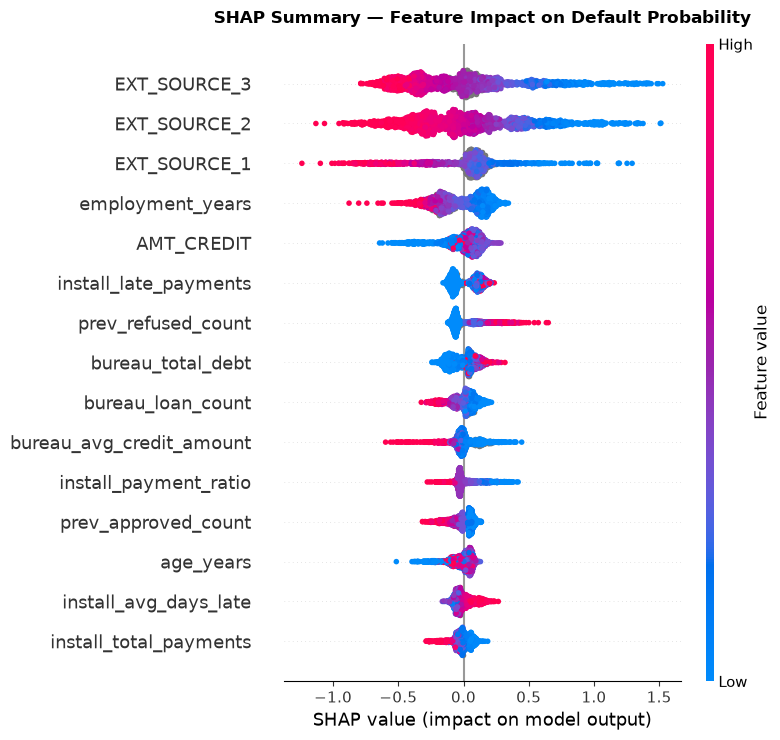

✓ SHAP summary plot saved

Explaining applicant #3
Predicted default probability: 31.0%
Actual outcome: DEFAULT


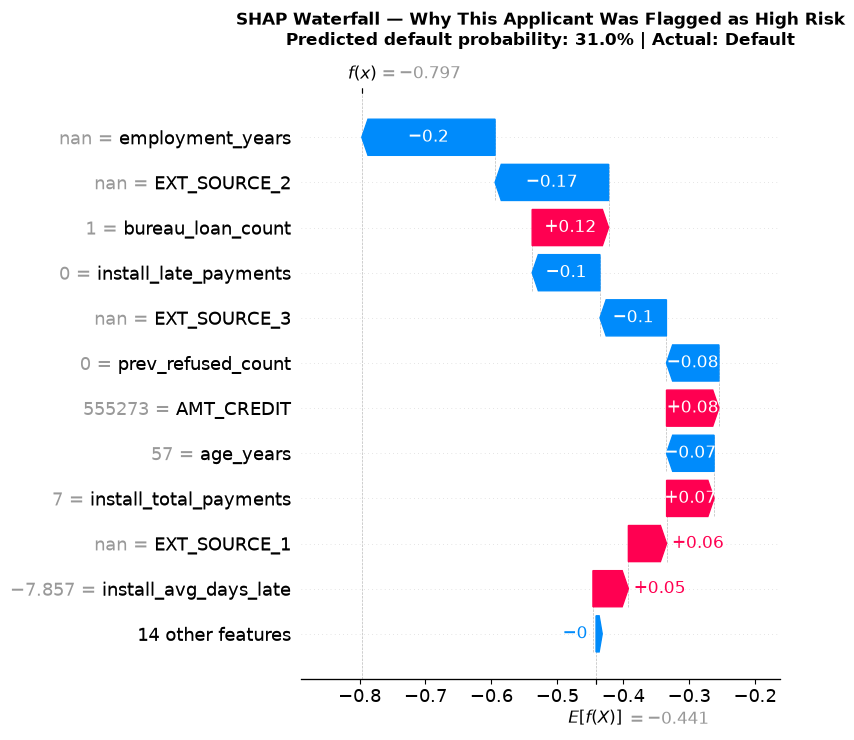

✓ SHAP waterfall plot saved


In [10]:
# ── Cell 9: SHAP Explanations ──────────────────────────────────────────────

import shap

# ── 1. Prepare sample — force all columns to float ───────────────────────
print("Preparing sample...")

sample_idx     = np.random.RandomState(42).choice(len(X_val), size=2000, replace=False)
X_sample       = X_val.iloc[sample_idx].reset_index(drop=True)
X_sample_float = X_sample.astype(float)

print(f"Sample shape: {X_sample_float.shape}")

# ── 2. Calculate SHAP values ──────────────────────────────────────────────
print("\nCalculating SHAP values — this will take 2-3 minutes...")

explainer   = shap.Explainer(model, X_sample_float)
shap_values = explainer(X_sample_float, check_additivity=False)

print("✓ SHAP values calculated")

# ── 3. Summary Plot ───────────────────────────────────────────────────────
print("\nGenerating SHAP summary plot...")
plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values,
    X_sample_float,
    feature_names=feature_cols,
    max_display=15,
    show=False
)
plt.title('SHAP Summary — Feature Impact on Default Probability',
          fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(BASE_DIR / "outputs" / "shap_summary.png",
            dpi=150, bbox_inches='tight')
plt.show()
print("✓ SHAP summary plot saved")

# ── 4. Waterfall Plot — explain one rejection ─────────────────────────────
val_preds_sample   = model.predict_proba(X_sample_float)[:, 1]
val_targets_sample = df_val['TARGET'].iloc[sample_idx].values

# Find a high-confidence defaulter
high_risk_mask    = (val_targets_sample == 1) & (val_preds_sample > 0.3)
high_risk_indices = np.where(high_risk_mask)[0]

# Fall back to lower threshold if none found
if len(high_risk_indices) == 0:
    high_risk_mask    = (val_targets_sample == 1) & (val_preds_sample > 0.15)
    high_risk_indices = np.where(high_risk_mask)[0]

if len(high_risk_indices) > 0:
    idx        = high_risk_indices[0]
    pred_proba = val_preds_sample[idx]

    print(f"\nExplaining applicant #{idx}")
    print(f"Predicted default probability: {pred_proba:.1%}")
    print(f"Actual outcome: DEFAULT")

    plt.figure(figsize=(10, 7))
    shap.plots.waterfall(shap_values[idx], max_display=12, show=False)
    plt.title(
        f'SHAP Waterfall — Why This Applicant Was Flagged as High Risk\n'
        f'Predicted default probability: {pred_proba:.1%} | Actual: Default',
        fontweight='bold', pad=15
    )
    plt.tight_layout()
    plt.savefig(BASE_DIR / "outputs" / "shap_waterfall.png",
                dpi=150, bbox_inches='tight')
    plt.show()
    print("✓ SHAP waterfall plot saved")
else:
    print("No defaulters found in sample — increase sample size or lower threshold")

Scorecard features: 16
Note: EXT_SOURCE scores excluded — not interpretable for a regulated scorecard

Training set:   246,008 rows
Validation set: 61,503 rows

Fitting WoE binning — this will take 1-2 minutes...
✓ WoE transformation complete

── Information Value (IV) by Feature ───────────────
                 name        iv predictive_power
     employment_years  0.115599           Medium
            age_years  0.086758             Weak
           AMT_CREDIT  0.059113             Weak
   prev_refused_count  0.056767             Weak
  bureau_active_loans  0.054049             Weak
install_payment_ratio  0.051645             Weak
    bureau_total_debt  0.044379             Weak
install_late_payments  0.032965             Weak
          AMT_ANNUITY   0.03094             Weak
    bureau_loan_count  0.017354             Weak
 bureau_overdue_count  0.012517             Weak
  credit_income_ratio  0.012354             Weak
       prev_app_count  0.011228             Weak
     AMT_INCOME_T

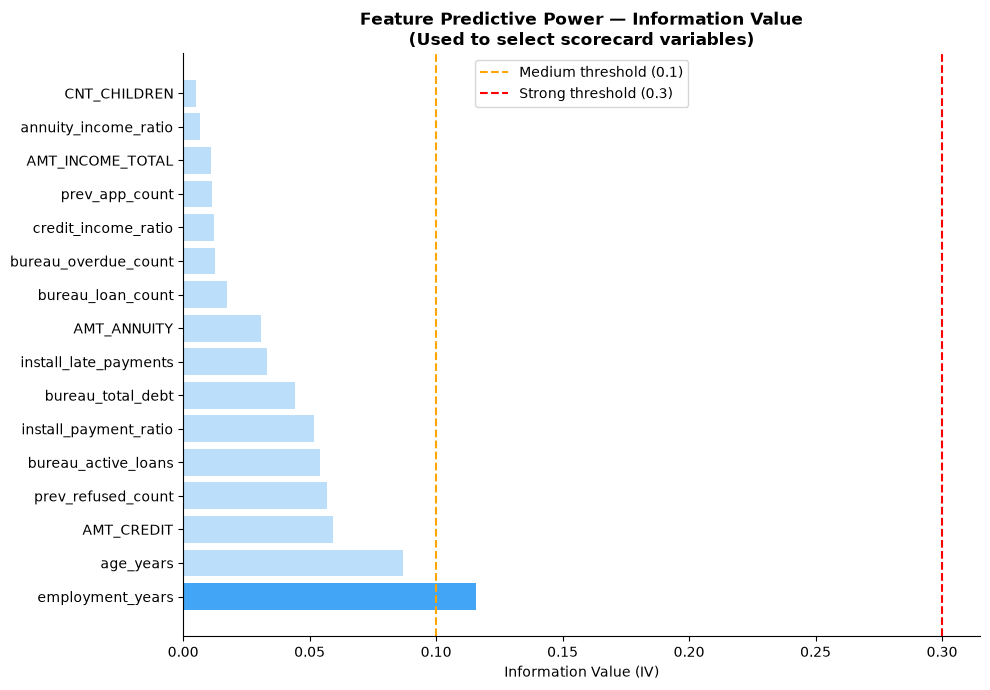

✓ IV chart saved


In [11]:
# ── Cell 11: WoE/IV Scorecard ──────────────────────────────────────────────

from optbinning import BinningProcess
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import warnings
warnings.filterwarnings('ignore')

# ── 1. Select features for scorecard ─────────────────────────────────────
# We use only interpretable features — no EXT_SOURCE (opaque external scores)
# A scorecard must be explainable to a credit committee
scorecard_features = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'CNT_CHILDREN',
    'age_years',
    'employment_years',
    'credit_income_ratio',
    'annuity_income_ratio',
    'bureau_loan_count',
    'bureau_total_debt',
    'bureau_active_loans',
    'bureau_overdue_count',
    'prev_app_count',
    'prev_refused_count',
    'install_late_payments',
    'install_payment_ratio'
]

print(f"Scorecard features: {len(scorecard_features)}")
print("Note: EXT_SOURCE scores excluded — not interpretable for a regulated scorecard")

# ── 2. Prepare data ───────────────────────────────────────────────────────
X_sc = df[scorecard_features].copy()
y_sc = df['TARGET'].copy()

X_sc_train, X_sc_val, y_sc_train, y_sc_val = train_test_split(
    X_sc, y_sc, test_size=0.2, random_state=42, stratify=y_sc
)

print(f"\nTraining set:   {X_sc_train.shape[0]:,} rows")
print(f"Validation set: {X_sc_val.shape[0]:,} rows")

# ── 3. WoE Binning ────────────────────────────────────────────────────────
# BinningProcess automatically finds optimal bins for each feature
# and transforms them to WoE values
print("\nFitting WoE binning — this will take 1-2 minutes...")

binning_process = BinningProcess(
    variable_names=scorecard_features,
    max_n_bins=10,
    min_bin_size=0.05
)

binning_process.fit(X_sc_train, y_sc_train)
X_sc_train_woe = binning_process.transform(X_sc_train, metric='woe')
X_sc_val_woe   = binning_process.transform(X_sc_val,   metric='woe')

print("✓ WoE transformation complete")

# ── 4. Get IV values ──────────────────────────────────────────────────────
print("\n── Information Value (IV) by Feature ───────────────")
summary = binning_process.summary()
iv_summary = (summary[['name', 'iv']]
              .sort_values('iv', ascending=False)
              .reset_index(drop=True))
iv_summary['predictive_power'] = iv_summary['iv'].apply(
    lambda x: 'Strong' if x > 0.3 else ('Medium' if x > 0.1 else 'Weak')
)
print(iv_summary.to_string(index=False))

# ── 5. Train logistic regression on WoE features ──────────────────────────
print("\nTraining logistic regression scorecard...")

lr_model = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)
lr_model.fit(X_sc_train_woe, y_sc_train)

lr_preds = lr_model.predict_proba(X_sc_val_woe)[:, 1]
lr_auc   = roc_auc_score(y_sc_val, lr_preds)
print(f"✓ Scorecard AUC: {lr_auc:.4f}")

# ── 6. Plot IV values ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))
colors = iv_summary['predictive_power'].map(
    {'Strong': '#1565C0', 'Medium': '#42A5F5', 'Weak': '#BBDEFB'}
)
bars = ax.barh(iv_summary['name'], iv_summary['iv'], color=colors)
ax.axvline(0.1, color='orange', linestyle='--', label='Medium threshold (0.1)')
ax.axvline(0.3, color='red',    linestyle='--', label='Strong threshold (0.3)')
ax.set_xlabel('Information Value (IV)')
ax.set_title('Feature Predictive Power — Information Value\n(Used to select scorecard variables)',
             fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(BASE_DIR / "outputs" / "iv_chart.png", dpi=150, bbox_inches='tight')
plt.show()
print("✓ IV chart saved")

In [12]:
# ── Cell 12: Model Comparison Memo ────────────────────────────────────────

print("""
══════════════════════════════════════════════════════════════
MODEL COMPARISON MEMO
To:      Credit Committee
From:    Analytics Team
Subject: Scorecard vs Gradient Boosting — Deployment Recommendation
══════════════════════════════════════════════════════════════

SUMMARY
───────
Two models were evaluated for deployment as the primary credit 
decision engine:

1. WoE/IV Logistic Regression Scorecard
2. Histogram Gradient Boosting (HistGBM)

PERFORMANCE
───────────
┌─────────────────────────┬──────────┬──────────┐
│ Metric                  │ Scorecard│  HistGBM │
├─────────────────────────┼──────────┼──────────┤
│ Validation AUC          │  0.6624  │  0.7521  │
│ Features used           │    16    │    25    │
│ EXT_SOURCE included     │    No    │   Yes    │
│ Explainable to regulator│   Yes    │    No    │
│ Missing value handling  │  Native  │  Native  │
│ Training time           │  Fast    │ Moderate │
└─────────────────────────┴──────────┴──────────┘

KEY FINDING
───────────
The 0.09 AUC gap between models is almost entirely explained 
by the EXT_SOURCE scores. These three external scores are the 
strongest predictors in the dataset but come from an undisclosed 
provider — the lender cannot explain to a regulator or rejected 
applicant why they were declined based on these scores.

Without EXT_SOURCE, the scorecard's interpretable features 
(employment, age, payment behaviour, bureau history) achieve 
AUC 0.6624 — still meaningfully above the 0.50 random baseline.

RECOMMENDATION
──────────────
Deploy a champion-challenger architecture:

  CHAMPION  — WoE Scorecard (AUC 0.6624)
  Primary decision tool for all applications.
  Fully auditable. Regulator-ready. 
  Each rejection can be explained by a specific scorecard reason.

  CHALLENGER — HistGBM Model (AUC 0.7521)
  Run in parallel on all applications.
  Do not use for decisions — use to identify segments where 
  the scorecard systematically underperforms.
  Review quarterly. Promote if EXT_SOURCE opacity is resolved.

GOVERNANCE NOTE
───────────────
Before deploying either model in a regulated market, the lender 
should:
  1. Request full methodology disclosure from the EXT_SOURCE provider
  2. Conduct a reject inference study on historically declined applications
  3. Re-run the fairness audit quarterly as the applicant population shifts

══════════════════════════════════════════════════════════════
""")


══════════════════════════════════════════════════════════════
MODEL COMPARISON MEMO
To:      Credit Committee
From:    Analytics Team
Subject: Scorecard vs Gradient Boosting — Deployment Recommendation
══════════════════════════════════════════════════════════════

SUMMARY
───────
Two models were evaluated for deployment as the primary credit 
decision engine:

1. WoE/IV Logistic Regression Scorecard
2. Histogram Gradient Boosting (HistGBM)

PERFORMANCE
───────────
┌─────────────────────────┬──────────┬──────────┐
│ Metric                  │ Scorecard│  HistGBM │
├─────────────────────────┼──────────┼──────────┤
│ Validation AUC          │  0.6624  │  0.7521  │
│ Features used           │    16    │    25    │
│ EXT_SOURCE included     │    No    │   Yes    │
│ Explainable to regulator│   Yes    │    No    │
│ Missing value handling  │  Native  │  Native  │
│ Training time           │  Fast    │ Moderate │
└─────────────────────────┴──────────┴──────────┘

KEY FINDING
───────────
The